In [15]:
from pathlib import Path
import sys
import json
import re

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))

from src.metrics.evaluator import Evaluator

In [16]:
def is_sample_valid(list_prediction: dict, list_goal: dict):
    return len(list_prediction) == len(list_goal)

In [17]:
def evaluate_valid_predictions(list_prediction: dict, list_goal: dict):
    if list_prediction.keys() != list_goal.keys():
        raise ValueError("list_prediction and list_goal must contain the same sample IDs")

    predictions = [list_prediction[sample_id] for sample_id in list_goal]
    golds = [list_goal[sample_id] for sample_id in list_goal]

    return Evaluator().evaluate_on_all_sample(predictions, golds)

In [18]:
import matplotlib.pyplot as plt


def checkpoint_number(name):
    numbers = re.findall(r"\d+", str(name))
    return int(numbers[-1]) if numbers else float("inf")


def plot_checkpoint_scores(score_lists: dict[str, dict[str, float]]):
    if not score_lists or any(not scores for scores in score_lists.values()):
        raise ValueError("score_lists and each score list must not be empty")

    fig, ax = plt.subplots(figsize=(14, 7))
    colors = {"GENEVA": "tab:blue", "VHE": "tab:orange"}

    for dataset_name, scores in score_lists.items():
        sorted_scores = sorted(
            scores.items(),
            key=lambda item: (checkpoint_number(item[0]), str(item[0])),
        )
        sorted_scores = sorted_scores[:10]
        epochs = list(range(1, len(sorted_scores) + 1))
        values = [score for _, score in sorted_scores]
        color = colors.get(dataset_name, "tab:green")

        ax.plot(
            epochs,
            values,
            marker="o",
            linestyle="None",
            color=color,
            label=dataset_name,
        )
        for index in range(len(values) - 1):
            ax.plot(
                epochs[index:index + 2],
                values[index:index + 2],
                color=color,
                linestyle="--" if values[index + 1] < values[index] else "-",
                label="_nolegend_",
            )
        for epoch, score in zip(epochs, values):
            ax.annotate(
                f"{score:.3f}",
                (epoch, score),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                fontsize=8,
                color=color,
            )

    ax.set_xticks(range(1, 11))
    ax.set_xticklabels([f"Epoch {epoch}" for epoch in range(1, 11)], rotation=45, ha="right")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Average F1")
    ax.set_title("Average F1 by Epoch: GENEVA vs VHE")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Dataset")
    fig.tight_layout()
    plt.show()

    return fig, ax

In [19]:
def load_goal(dataset_name: str):
    path = ROOT / "data" / "processed" / dataset_name / "dev.jsonl"
    with path.open("r", encoding="utf-8") as f:
        goal = [json.loads(line) for line in f]

    list_goal = {
        sample["id"]: {"events": sample["events"]}
        for sample in goal
    }
    print(f"Loaded {len(list_goal)} {dataset_name} goal samples")
    return list_goal


list_goals = {
    "GENEVA": load_goal("GENEVA"),
    "VHE": load_goal("VHE"),
}

Loaded 766 GENEVA goal samples
Loaded 406 VHE goal samples


In [20]:
prediction_folders = {
    "GENEVA": ROOT / "model" / "Valid_OUPUT_GENEVA" / "ee_valid_results",
    "VHE": ROOT / "model" / "Valid_OUPUT_VHE",
}

score_lists = {}
for dataset_name, folder_valid_results in prediction_folders.items():
    list_goal = list_goals[dataset_name]
    score_list = {}
    file_names = [file.name for file in folder_valid_results.iterdir() if file.is_file()]

    for file in file_names:
        path = folder_valid_results / file
        with path.open("r", encoding="utf-8") as f:
            prediction = [json.loads(line) for line in f]

        list_prediction = {
            sample["id"]: sample["result"]
            for sample in prediction
        }

        valid = is_sample_valid(list_prediction, list_goal)
        print(
            f"{dataset_name} checkpoint {file} valid test have "
            f"{len(list_prediction)} -> {valid}"
        )
        if valid:
            score = evaluate_valid_predictions(
                list_prediction=list_prediction,
                list_goal=list_goal,
            )
            print(f"{dataset_name} score of {file} = {score['avg_f1']}")
            score_list[file] = score["avg_f1"]

    score_lists[dataset_name] = score_list

print(score_lists)

GENEVA checkpoint val_checkpoint-1175.jsonl valid test have 766 -> True
GENEVA score of val_checkpoint-1175.jsonl = 0.34729433717339997
GENEVA checkpoint val_checkpoint-1410.jsonl valid test have 766 -> True
GENEVA score of val_checkpoint-1410.jsonl = 0.38208103988811826
GENEVA checkpoint val_checkpoint-1645.jsonl valid test have 766 -> True
GENEVA score of val_checkpoint-1645.jsonl = 0.38752186610056877
GENEVA checkpoint val_checkpoint-1880.jsonl valid test have 766 -> True
GENEVA score of val_checkpoint-1880.jsonl = 0.4112724785563926
GENEVA checkpoint val_checkpoint-2115.jsonl valid test have 766 -> True
GENEVA score of val_checkpoint-2115.jsonl = 0.40605422269970454
GENEVA checkpoint val_checkpoint-235.jsonl valid test have 766 -> True
GENEVA score of val_checkpoint-235.jsonl = 0.18968931007189466
GENEVA checkpoint val_checkpoint-2350.jsonl valid test have 766 -> True
GENEVA score of val_checkpoint-2350.jsonl = 0.41832023625430276
GENEVA checkpoint val_checkpoint-2585.jsonl valid t

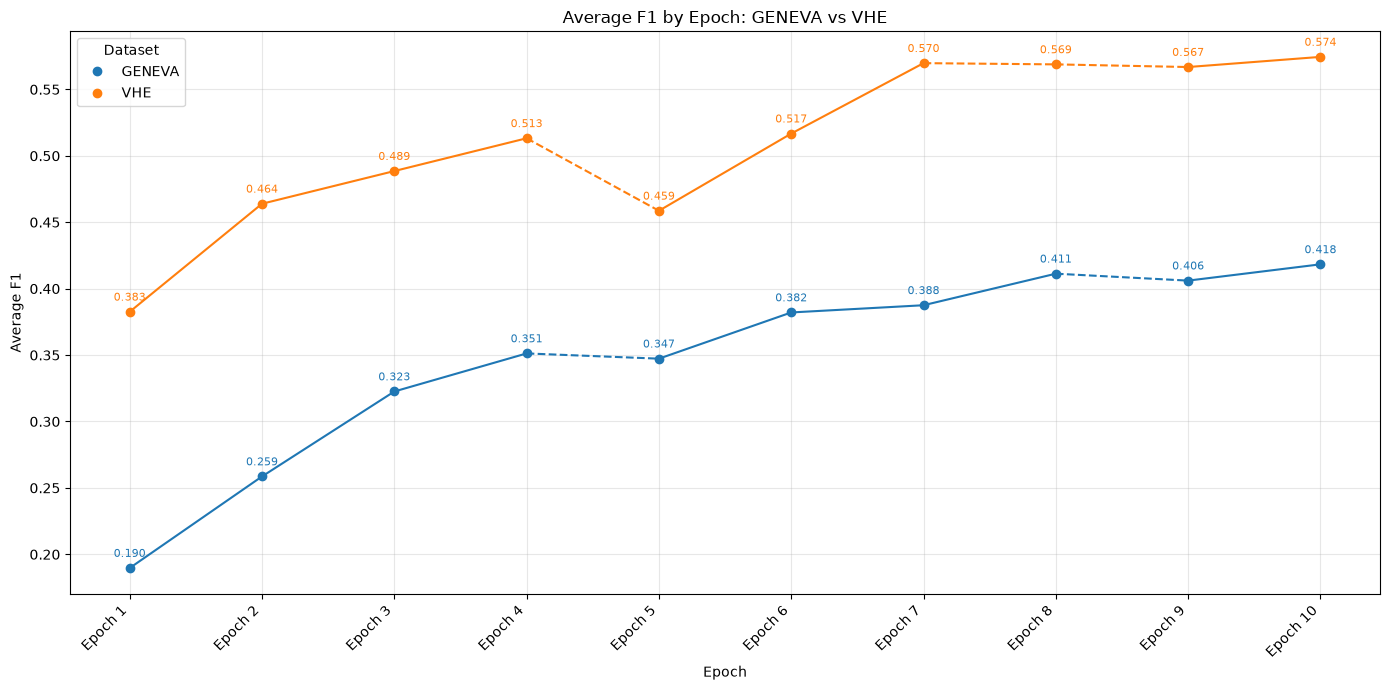

In [21]:
fig, ax = plot_checkpoint_scores(score_lists)